**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053.10 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Profesora titular: Dra. Grettel Barceló

Profesor tutor: Mtro. Roberto Antonio Guevara González

**Semana 6**  
Ingeniería de características

---

**Equipo 5:**
- Alejandro Santiago Baca Eyssautier - A01656580
- Andrea Guadalupe Ayala Govea - A01203657
- Arturo Ávila Sánchez - A01841717
- Cristobal Jared Aviles Salgado - A01635702

<br>

En esta actividad trabajarás con el archivo `computer_prices.csv`, basado en un conjunto de datos sobre características técnicas y especificaciones de computadoras portátiles y de escritorio, disponible en Kaggle.

Los datos fueron recopilados para analizar el rendimiento y el precio de los dispositivos, e incluyen información sobre hardware, almacenamiento, conectividad y otras especificaciones técnicas. Los indicadores incluidos son:

* `device_type`: Tipo de dispositivo (ej. laptop, desktop)
* `brand`: Marca del dispositivo
* `model`: Modelo del dispositivo
* `release_year`: Año de lanzamiento del dispositivo
* `os`: Sistema operativo instalado
* `form_factor`: Factor de forma o diseño del dispositivo (ej. laptop, ultrabook, desktop tower)
* `cpu_brand`: Marca del procesador
* `cpu_tier`: Nivel o gama del procesador, ordinal del 1 al 6 según desempeño
* `cpu_cores`: Número de núcleos del procesador
* `cpu_threads`: Número de hilos de ejecución del procesador
* `gpu_brand`: Marca de la tarjeta gráfica
* `gpu_model`: Modelo específico de la tarjeta gráfica
* `gpu_tier`: Nivel o gama de la GPU, ordinal del 1 al 6 según desempeño
* `vram_gb`: Memoria de video de la GPU en gigabytes
* `ram_gb`: Memoria RAM del dispositivo en gigabytes
* `storage_type`: Tipo de almacenamiento (ej. HDD, SSD)
* `storage_gb`: Capacidad de almacenamiento en gigabytes
* `storage_drive_count`: Número de unidades de almacenamiento instaladas
* `display_type`: Tipo de pantalla (ej. IPS, TN, OLED)
* `charger_watts`: Potencia del cargador (en watts) para laptops
* `psu_watts`: Potencia de la fuente de poder (en watts) para desktops
* `wifi`: Estándar de conectividad Wi-Fi (ej. Wi-Fi 5, 6, 6E, 7)
* `bluetooth`: Versión de Bluetooth
* `weight_kg`: Peso del dispositivo en kilogramos
* `warranty_months`: Meses de garantía del dispositivo
* `price`: Precio del dispositivo. Es la variable de salida o *target*, es decir, la que se pretende predecir más adelante al construir el modelo.

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [1]:
import importlib.util
import subprocess
import sys

if importlib.util.find_spec('category_encoders') is None:
    subprocess.run(
        [sys.executable, '-m', 'pip', 'install', '-q', 'category_encoders'],
        check=True,
        stdout=subprocess.DEVNULL,
        stderr=subprocess.DEVNULL
    )

In [2]:
import warnings
warnings.filterwarnings('ignore')

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import probplot
from sklearn.preprocessing import KBinsDiscretizer
from sklearn.preprocessing import FunctionTransformer, PowerTransformer
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from category_encoders.binary import BinaryEncoder
from IPython.display import display

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda value: f'{value:,.4f}')
sns.set_theme(style='whitegrid')

1. Descarga el archivo: `computer_prices.csv` y guarda, en un dataframe (`compu_df`), todos sus registros.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?
* Determina la cantidad de valores únicos por columna.
* Elimina las variables:
  * `model`: Debido a su altísima cardinalidad, lo que dificulta su uso en análisis y modelado.
  * `cpu_model`: Además de su elevada cardinalidad, su información ya está representada de manera implícita en otras variables como: `cpu_tier`, `cpu_cores` y `cpu_threads`

In [3]:
ruta_datos = Path('computer_prices.csv')
compu_df = pd.read_csv(ruta_datos)

print(f'Dimensiones iniciales: {compu_df.shape}')
compu_df.info()

num_iniciales = compu_df.select_dtypes(include=np.number).columns.tolist()
texto_iniciales = compu_df.select_dtypes(include='object').columns.tolist()

print(f'Columnas numéricas: {len(num_iniciales)}')
print(f'Columnas de texto: {len(texto_iniciales)}')

display(compu_df.nunique().to_frame('valores_unicos'))

compu_df = compu_df.drop(columns=['model', 'cpu_model'])
print(f'Dimensiones después de eliminar model y cpu_model: {compu_df.shape}')

Dimensiones iniciales: (100000, 27)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 27 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   device_type          100000 non-null  object 
 1   brand                100000 non-null  object 
 2   model                100000 non-null  object 
 3   release_year         100000 non-null  int64  
 4   os                   100000 non-null  object 
 5   form_factor          100000 non-null  object 
 6   cpu_brand            100000 non-null  object 
 7   cpu_model            100000 non-null  object 
 8   cpu_tier             100000 non-null  int64  
 9   cpu_cores            100000 non-null  int64  
 10  cpu_threads          100000 non-null  int64  
 11  gpu_brand            100000 non-null  object 
 12  gpu_model            100000 non-null  object 
 13  gpu_tier             100000 non-null  int64  
 14  vram_gb              100000 non-n

,valores_unicos
device_type,2
brand,10
model,99036
release_year,8
os,4
form_factor,10
cpu_brand,3
cpu_model,26971
cpu_tier,6
cpu_cores,12


Dimensiones después de eliminar model y cpu_model: (100000, 25)


**Análisis.** El dataframe contiene 100,000 dispositivos y 27 variables: 15 columnas numéricas y 12 de texto. `model` presenta 99,036 valores únicos y `cpu_model` 26,971, por lo que ambas columnas generarían una representación excesivamente dispersa. Además, las variables de desempeño del procesador ya resumen buena parte de la información de `cpu_model`; por ello se eliminan ambas antes del análisis.

2. Antes de iniciar con el análisis univariado, verifica si hay valores duplicados y/o faltantes.
* Obtén las estadísticas descriptivas, separado las numéricas y las categóricas. De estas últimas incluye las tablas de frecuencia.
* Genera histogramas para las numéricas y diagramas de barras para las categóricas. Con alta cardinalidad, sólo incluye los 10 valores más frecuentes.

Registros duplicados: 0
Valores faltantes totales: 0


,faltantes
device_type,0
brand,0
release_year,0
os,0
form_factor,0
cpu_brand,0
cpu_tier,0
cpu_cores,0
cpu_threads,0
gpu_brand,0


Estadísticas descriptivas de variables numéricas


,count,mean,std,min,25%,50%,75%,max
release_year,"100,000.0000","2,022.3209",2.0258,"2,018.0000","2,021.0000","2,023.0000","2,024.0000","2,025.0000"
cpu_tier,"100,000.0000",3.1535,1.3732,1.0000,2.0000,3.0000,4.0000,6.0000
cpu_cores,"100,000.0000",10.5157,5.0441,4.0000,6.0000,8.0000,14.0000,28.0000
cpu_threads,"100,000.0000",19.3727,9.7184,4.0000,12.0000,16.0000,24.0000,56.0000
gpu_tier,"100,000.0000",2.9914,1.4596,1.0000,2.0000,3.0000,4.0000,6.0000
vram_gb,"100,000.0000",6.1522,3.9649,0.0000,4.0000,6.0000,8.0000,16.0000
ram_gb,"100,000.0000",39.7064,31.9027,8.0000,16.0000,32.0000,64.0000,144.0000
storage_gb,"100,000.0000",903.9360,774.2437,256.0000,512.0000,512.0000,"1,024.0000","4,096.0000"
storage_drive_count,"100,000.0000",1.5250,0.7973,1.0000,1.0000,1.0000,2.0000,4.0000
charger_watts,"100,000.0000",61.3835,62.7950,0.0000,0.0000,65.0000,90.0000,240.0000


Estadísticas descriptivas de variables categóricas


...

,frecuencia,porcentaje
storage_type,,
NVMe,45059,45.0590
SSD,24937,24.9370
HDD,15023,15.0230
Hybrid,14981,14.9810


display_type


,frecuencia,porcentaje
display_type,,
LED,32000,32.0000
OLED,21910,21.9100
IPS,17742,17.7420
Mini-LED,12188,12.1880
QLED,10069,10.0690
VA,6091,6.0910


wifi


,frecuencia,porcentaje
wifi,,
Wi-Fi 6,46149,46.1490
Wi-Fi 6E,25923,25.9230
Wi-Fi 5,19926,19.9260
Wi-Fi 7,8002,8.0020


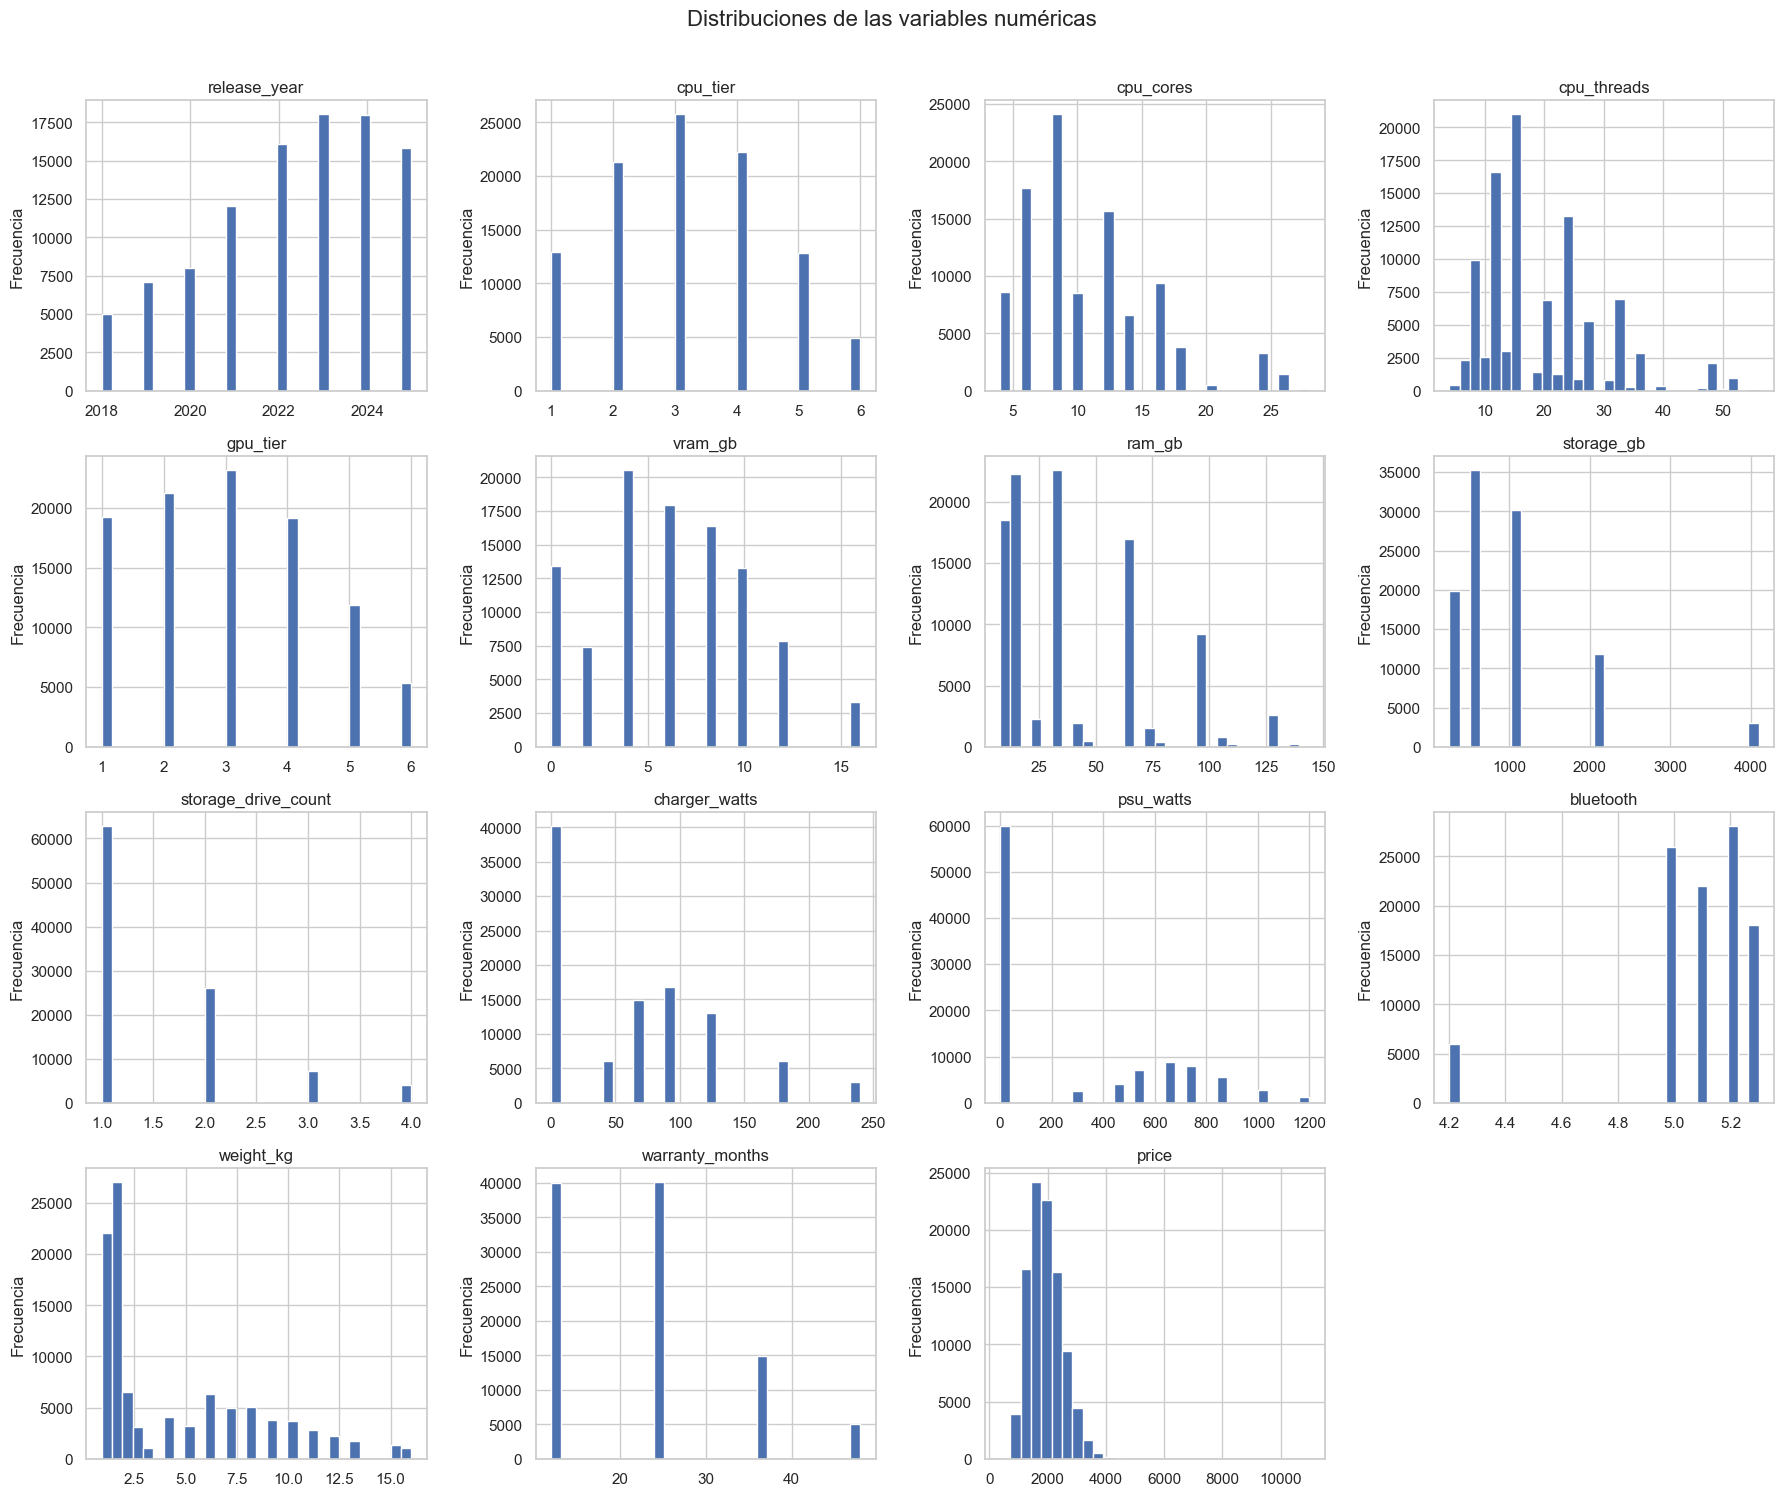

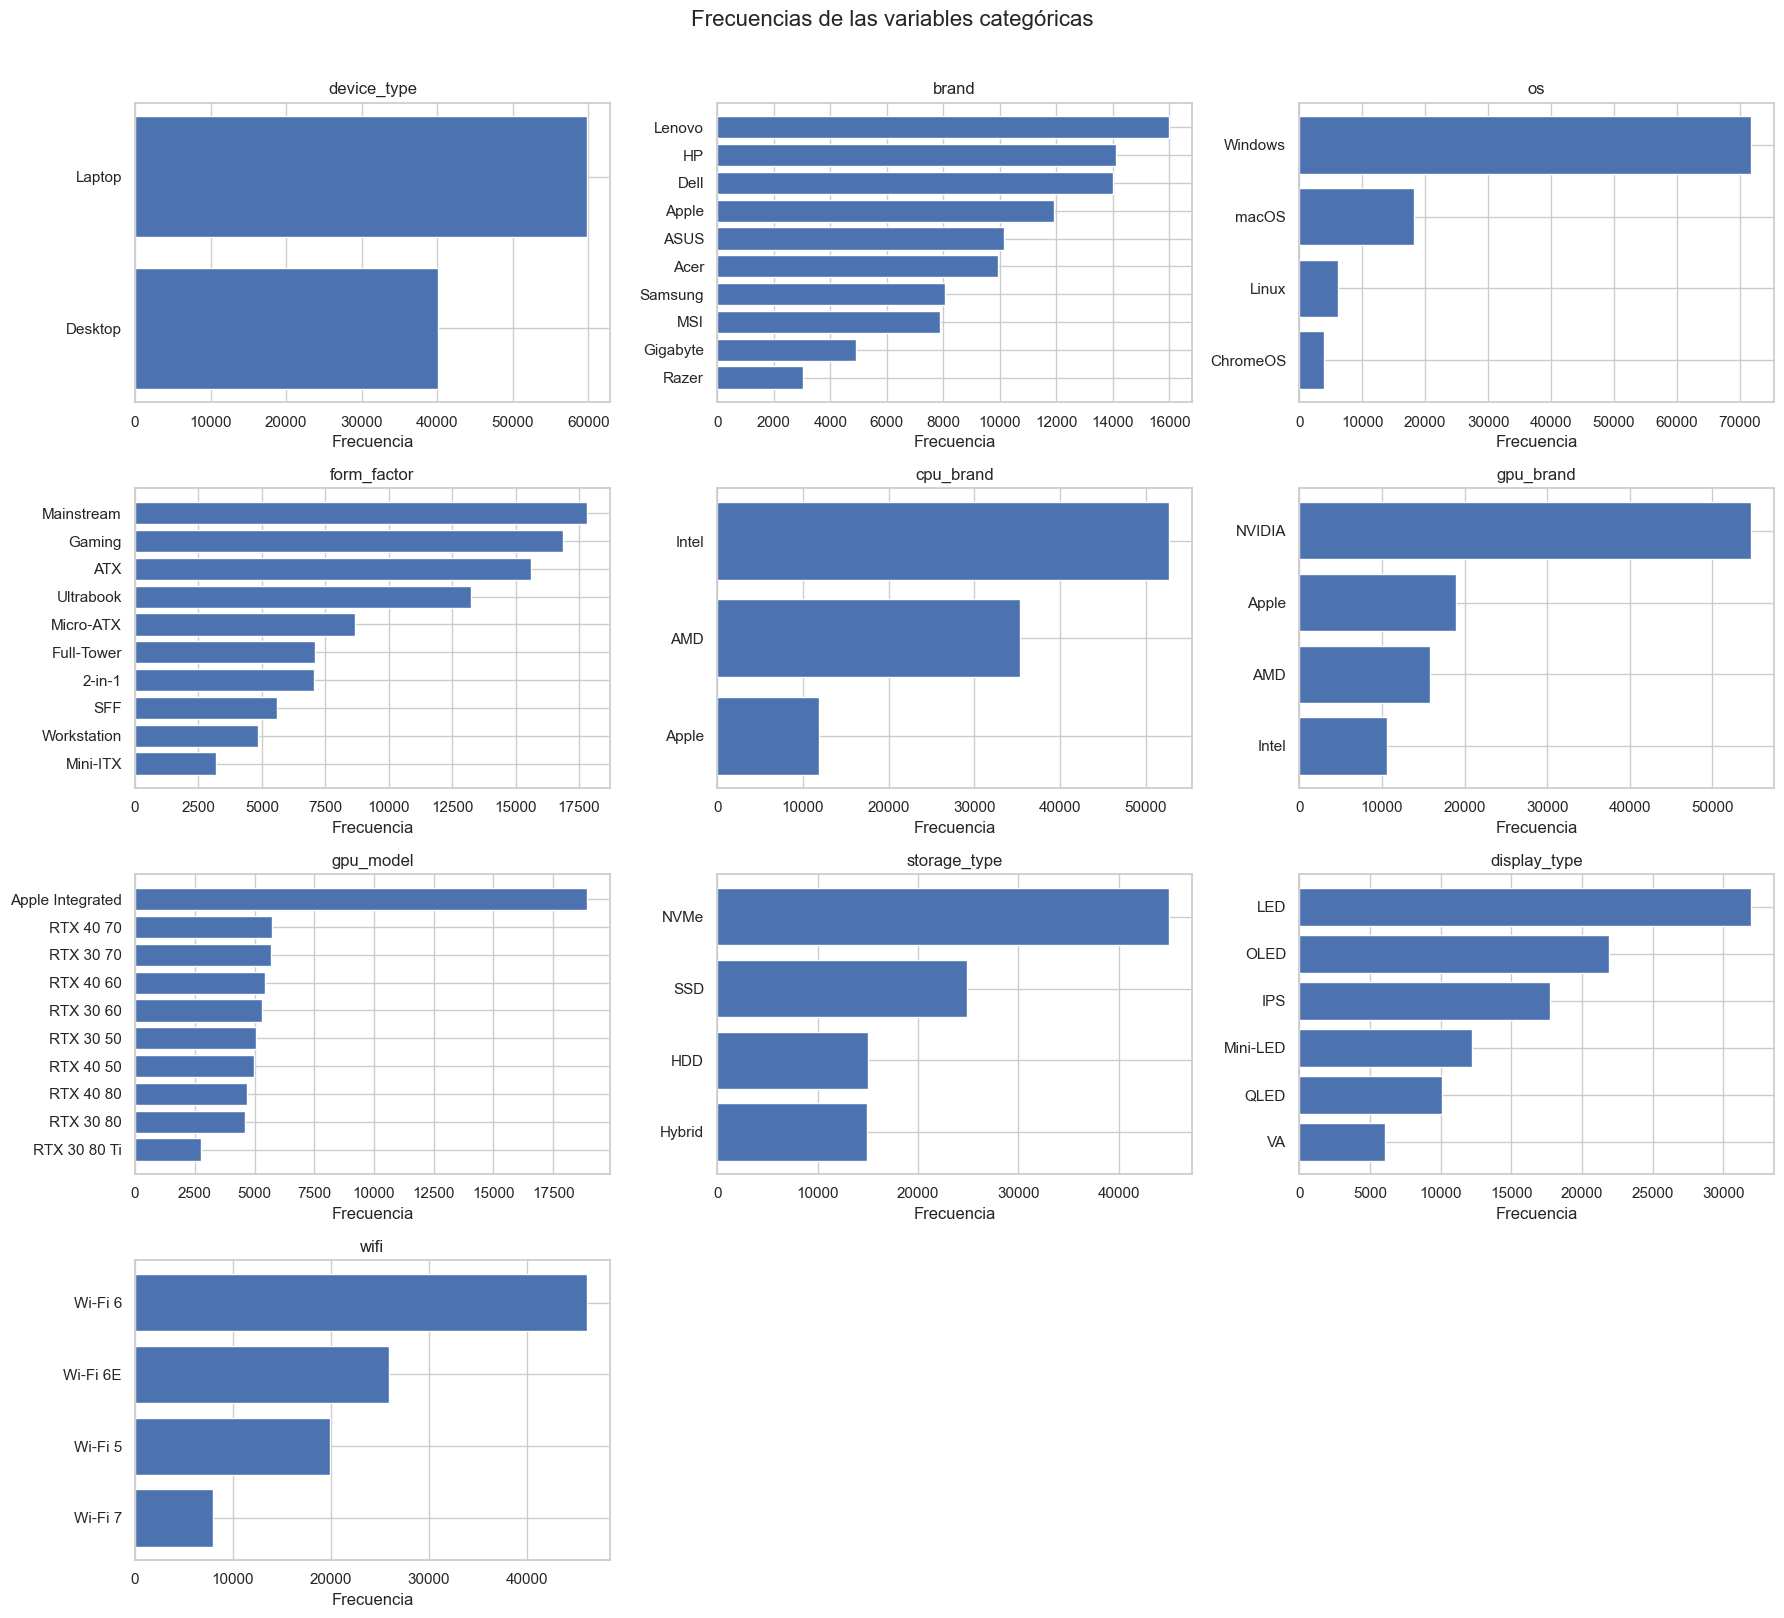

In [4]:
duplicados = compu_df.duplicated().sum()
faltantes = compu_df.isna().sum()

print(f'Registros duplicados: {duplicados}')
print(f'Valores faltantes totales: {int(faltantes.sum())}')
display(faltantes.to_frame('faltantes'))

numericas = compu_df.select_dtypes(include=np.number).columns.tolist()
categoricas = compu_df.select_dtypes(include='object').columns.tolist()

print('Estadísticas descriptivas de variables numéricas')
display(compu_df[numericas].describe().T)

print('Estadísticas descriptivas de variables categóricas')
display(compu_df[categoricas].describe().T)

frecuencias = {}
for columna in categoricas:
    tabla = compu_df[columna].value_counts().head(10).to_frame('frecuencia')
    tabla['porcentaje'] = 100 * tabla['frecuencia'] / len(compu_df)
    frecuencias[columna] = tabla
    print(columna)
    display(tabla)

filas = int(np.ceil(len(numericas) / 4))
fig, axes = plt.subplots(filas, 4, figsize=(18, 3.7 * filas))
axes = np.array(axes).reshape(-1)
for eje, columna in zip(axes, numericas):
    eje.hist(compu_df[columna], bins=30, edgecolor='white')
    eje.set_title(columna)
    eje.set_ylabel('Frecuencia')
for eje in axes[len(numericas):]:
    eje.set_visible(False)
plt.suptitle('Distribuciones de las variables numéricas', y=1.01, fontsize=16)
plt.tight_layout()
plt.show()

filas_cat = int(np.ceil(len(categoricas) / 3))
fig, axes = plt.subplots(filas_cat, 3, figsize=(18, 4 * filas_cat))
axes = np.array(axes).reshape(-1)
for eje, columna in zip(axes, categoricas):
    conteos = compu_df[columna].value_counts().head(10).sort_values()
    eje.barh(conteos.index.astype(str), conteos.values)
    eje.set_title(columna)
    eje.set_xlabel('Frecuencia')
for eje in axes[len(categoricas):]:
    eje.set_visible(False)
plt.suptitle('Frecuencias de las variables categóricas', y=1.01, fontsize=16)
plt.tight_layout()
plt.show()

**Análisis.** No se identificaron registros duplicados ni valores faltantes. Las distribuciones iniciales muestran que varias medidas de capacidad tienen asimetría positiva, mientras que las variables categóricas están concentradas en unas cuantas categorías dominantes. En `gpu_model`, que tiene 49 categorías, se muestran únicamente las diez más frecuentes para conservar legibilidad.

3. Dibuja un mapa de calor con la matriz de correlación para las variables numéricas del conjunto de datos.
* Identifica los pares de variables cuya correlación sea superior a 0.9 e imprímelos.
* Reflexiona sobre cuáles variables, de las que se imprimieron, representan de manera general la capacidad del hardware y mantenlas; elimina las demás por aportar información redundante.
* Incluye una breve justificación de tus decisiones.

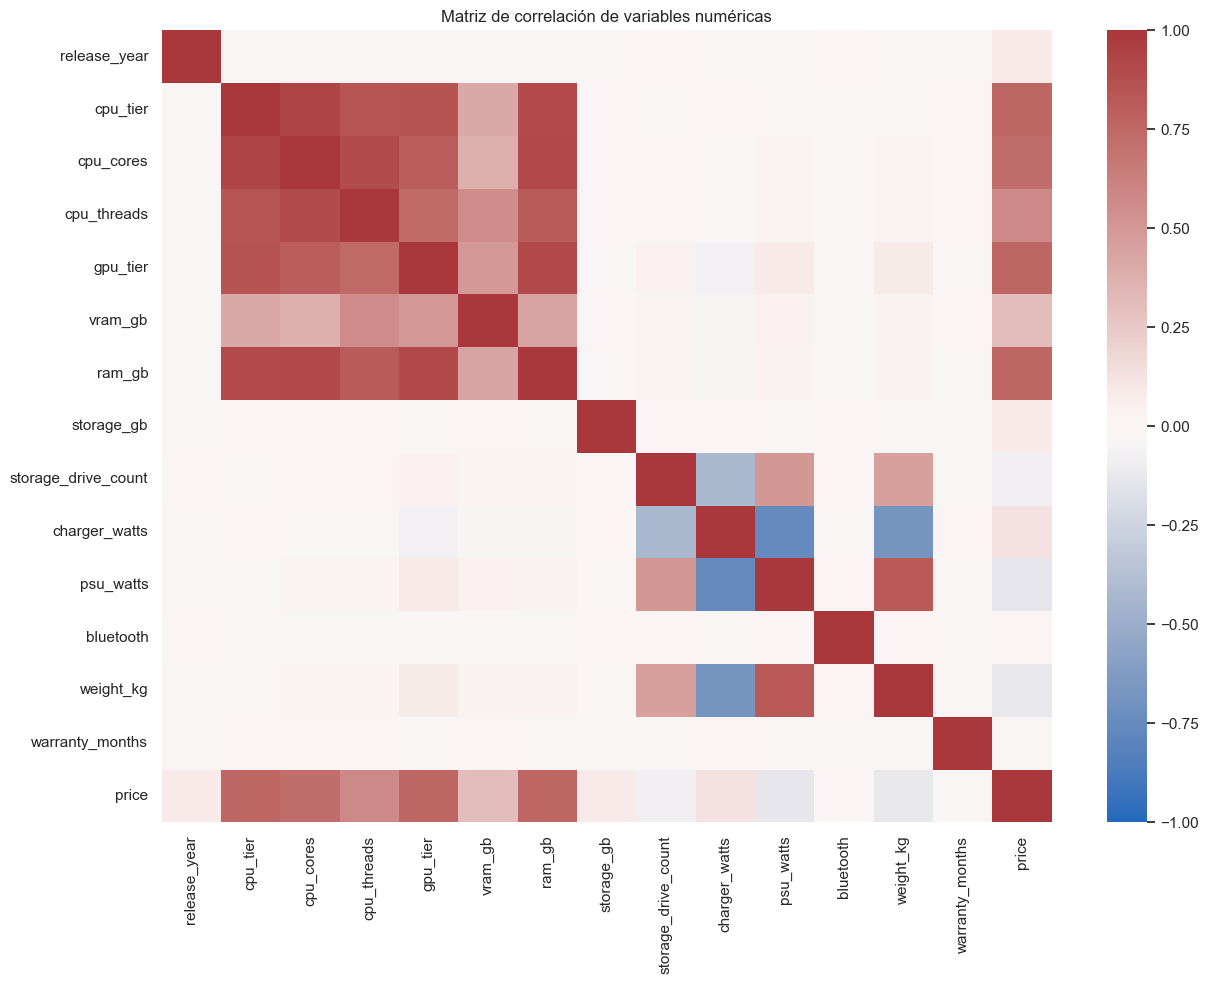

,variable_1,variable_2,correlacion
14,cpu_tier,cpu_cores,0.9374
51,gpu_tier,ram_gb,0.9129
30,cpu_cores,ram_gb,0.9068


Columnas eliminadas por redundancia: cpu_cores y ram_gb
Dimensiones después de la selección: (100000, 23)


In [5]:
corr = compu_df.select_dtypes(include=np.number).corr()

plt.figure(figsize=(13, 10))
sns.heatmap(corr, cmap='vlag', center=0, vmin=-1, vmax=1)
plt.title('Matriz de correlación de variables numéricas')
plt.tight_layout()
plt.show()

mascara = np.triu(np.ones(corr.shape, dtype=bool), k=1)
pares_correlacion = (
    corr.where(mascara)
    .stack()
    .rename('correlacion')
    .reset_index()
    .rename(columns={'level_0': 'variable_1', 'level_1': 'variable_2'})
)
pares_altos = pares_correlacion[
    pares_correlacion['correlacion'].abs() > 0.9
].sort_values('correlacion', ascending=False)

display(pares_altos)

compu_df = compu_df.drop(columns=['cpu_cores', 'ram_gb'])
print(f'Columnas eliminadas por redundancia: cpu_cores y ram_gb')
print(f'Dimensiones después de la selección: {compu_df.shape}')

**Decisión de selección.** Los pares con correlación absoluta superior a 0.90 son `cpu_tier`–`cpu_cores` (0.937), `gpu_tier`–`ram_gb` (0.913) y `cpu_cores`–`ram_gb` (0.907). Se conservan `cpu_tier` y `gpu_tier` porque sintetizan de forma ordinal el nivel general de desempeño del procesador y de la GPU. Se eliminan `cpu_cores` y `ram_gb`, que aportan información altamente redundante dentro de este conjunto. `cpu_threads` se conserva porque su correlación no supera el umbral establecido y todavía describe paralelismo de ejecución.

4. Para comenzar con la ingeniería de características, crea una copia del dataframe y asígnala a un nuevo objeto llamado `compu_transf`.
* Calcula cuántos años han pasado desde el lanzamiento de cada computadora y almacénalo en una nueva columna llamada `years_since_release`; luego, elimina la columna original.
* Utiliza `KBinsDiscretizer` para reemplazar la columna `vram_gb` en 4 bins ordinales basados en cuantiles.
* Imprime los valores que delimitan cada bin y haz un gráfico de barras para ver la cantidad de observaciones en cada uno, con el fin de entender cómo se agruparon los datos.

Límites de los bins de vram_gb:
[ 0.  4.  6.  8. 16.]


,observaciones
vram_gb,
1,20757
2,20517
3,17930
4,40796


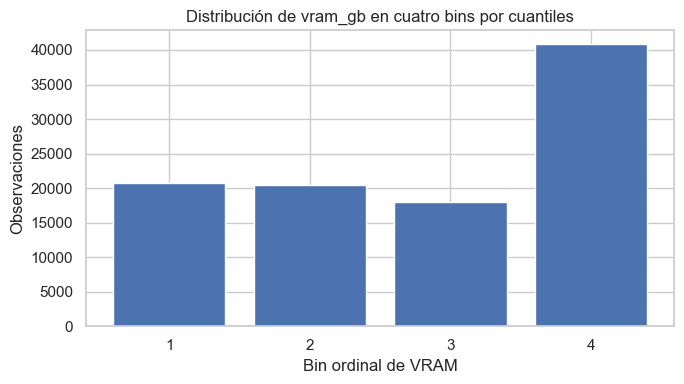

In [6]:
compu_transf = compu_df.copy()

anio_referencia = 2026
compu_transf['years_since_release'] = anio_referencia - compu_transf['release_year']
compu_transf = compu_transf.drop(columns='release_year')

discretizador_vram = KBinsDiscretizer(
    n_bins=4,
    encode='ordinal',
    strategy='quantile'
)
compu_transf['vram_gb'] = (
    discretizador_vram
    .fit_transform(compu_transf[['vram_gb']])
    .ravel()
    .astype(int)
    + 1
)

limites_vram = discretizador_vram.bin_edges_[0]
print('Límites de los bins de vram_gb:')
print(limites_vram)

distribucion_vram = compu_transf['vram_gb'].value_counts().sort_index()
display(distribucion_vram.to_frame('observaciones'))

plt.figure(figsize=(7, 4))
plt.bar(distribucion_vram.index.astype(str), distribucion_vram.values)
plt.xlabel('Bin ordinal de VRAM')
plt.ylabel('Observaciones')
plt.title('Distribución de vram_gb en cuatro bins por cuantiles')
plt.tight_layout()
plt.show()

**Análisis.** Los cuatro intervalos de VRAM quedan delimitados por 0, 4, 6, 8 y 16 GB. La discretización convierte una capacidad con valores puntuales en una escala ordinal de cuatro niveles. El último bin concentra más observaciones porque incluye todas las configuraciones superiores a 8 GB hasta el máximo de 16 GB.

5. Observa los histogramas del ejercicio 2. Notarás que en las variables `charger_watts` y `psu_watts` aparece una barra en 0. Analiza por qué ocurre esto y qué significa en relación con el tipo de dispositivo.
* Como estas variables son mutuamente excluyentes, combínalas en una nueva columna llamada `power_watts` que contenga la potencia correspondiente de cada dispositivo y, a continuación, haz un histograma para verificar que la distribución resultante es bimodal.
* Por último, borra las columnas originales `charger_watts` y `psu_watts`.

charger_watts              psu_watts               
                      min  median  max       min   median   max
device_type                                                    
Desktop                 0  0.0000    0       300 650.0000  1200
Laptop                 45 90.0000  240         0   0.0000     0

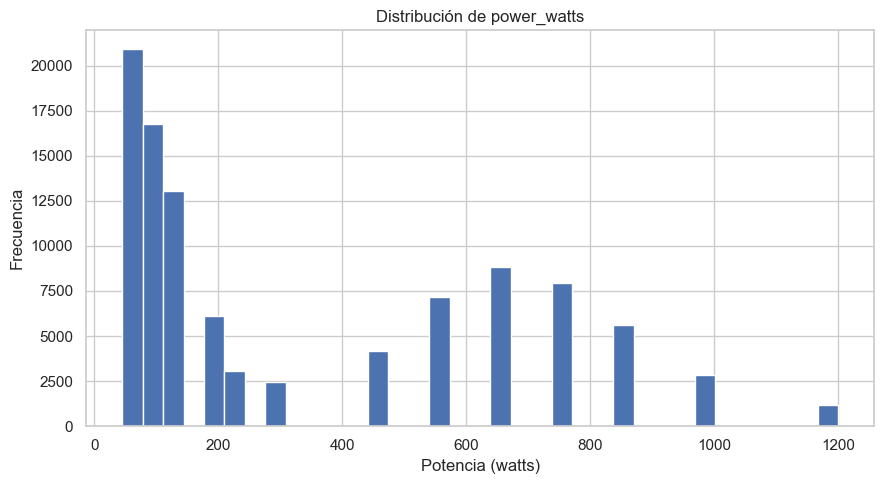

Resumen de power_watts por tipo de dispositivo


,count,mean,std,min,25%,50%,75%,max
device_type,,,,,,,,
Desktop,"40,156.0000",678.6545,194.0550,300.0000,550.0000,650.0000,750.0000,"1,200.0000"
Laptop,"59,844.0000",102.5724,48.6238,45.0000,65.0000,90.0000,120.0000,240.0000


In [7]:
potencia_por_tipo = compu_transf.groupby('device_type')[
    ['charger_watts', 'psu_watts']
].agg(['min', 'median', 'max'])
display(potencia_por_tipo)

compu_transf['power_watts'] = (
    compu_transf['charger_watts'] + compu_transf['psu_watts']
)
compu_transf = compu_transf.drop(columns=['charger_watts', 'psu_watts'])

plt.figure(figsize=(9, 5))
plt.hist(compu_transf['power_watts'], bins=35, edgecolor='white')
plt.xlabel('Potencia (watts)')
plt.ylabel('Frecuencia')
plt.title('Distribución de power_watts')
plt.tight_layout()
plt.show()

print('Resumen de power_watts por tipo de dispositivo')
display(compu_transf.groupby('device_type')['power_watts'].describe())

**Análisis.** Los ceros no representan ausencia real de potencia: son una consecuencia del tipo de dispositivo. Las laptops utilizan `charger_watts` y tienen `psu_watts` igual a cero; las desktops presentan el patrón inverso. Al sumarlas se obtiene una sola variable válida por registro. La distribución resultante es bimodal porque las laptops se concentran alrededor de potencias bajas, mientras que las desktops requieren fuentes considerablemente mayores.

6. Para disminuir el sesgo de la variable `price`, crea tres transformadores: logaritmo, raíz cuadrada y Box - Cox.
* Aplica cada transformador a la variable price, dejando el resultado en variables temporales. El objetivo es comparar los efectos de cada transformación antes de decidir cuál aplicar de manera definitiva sobre las variables continuas del dataframe.
* De la variable original y de cada una de las tres transformaciones se debe mostrar:
  * Histograma: para observar la distribución de los datos.
  * Boxplot: para identificar posibles valores atípicos.
  * Q-Q plot: para evaluar la normalidad de la variable.
  * Skew (sesgo): para cuantificar la asimetría de la distribución.
  * Cantidad de outliers: para conocer cuántos valores extremos existen.
* En función de los resultados obtenidos al comparar las transformaciones, decide cuál logró el mejor efecto sobre la distribución de la variable y aplícala directamente en el dataframe, reemplazando las variables continuas: `weight_kg`, `power_watts` y `price`.

,skew,outliers
Original,0.9866,976.0000
Logaritmo,-0.1326,387.0000
Raíz cuadrada,0.3323,364.0000
Box-Cox,-0.0002,317.0000


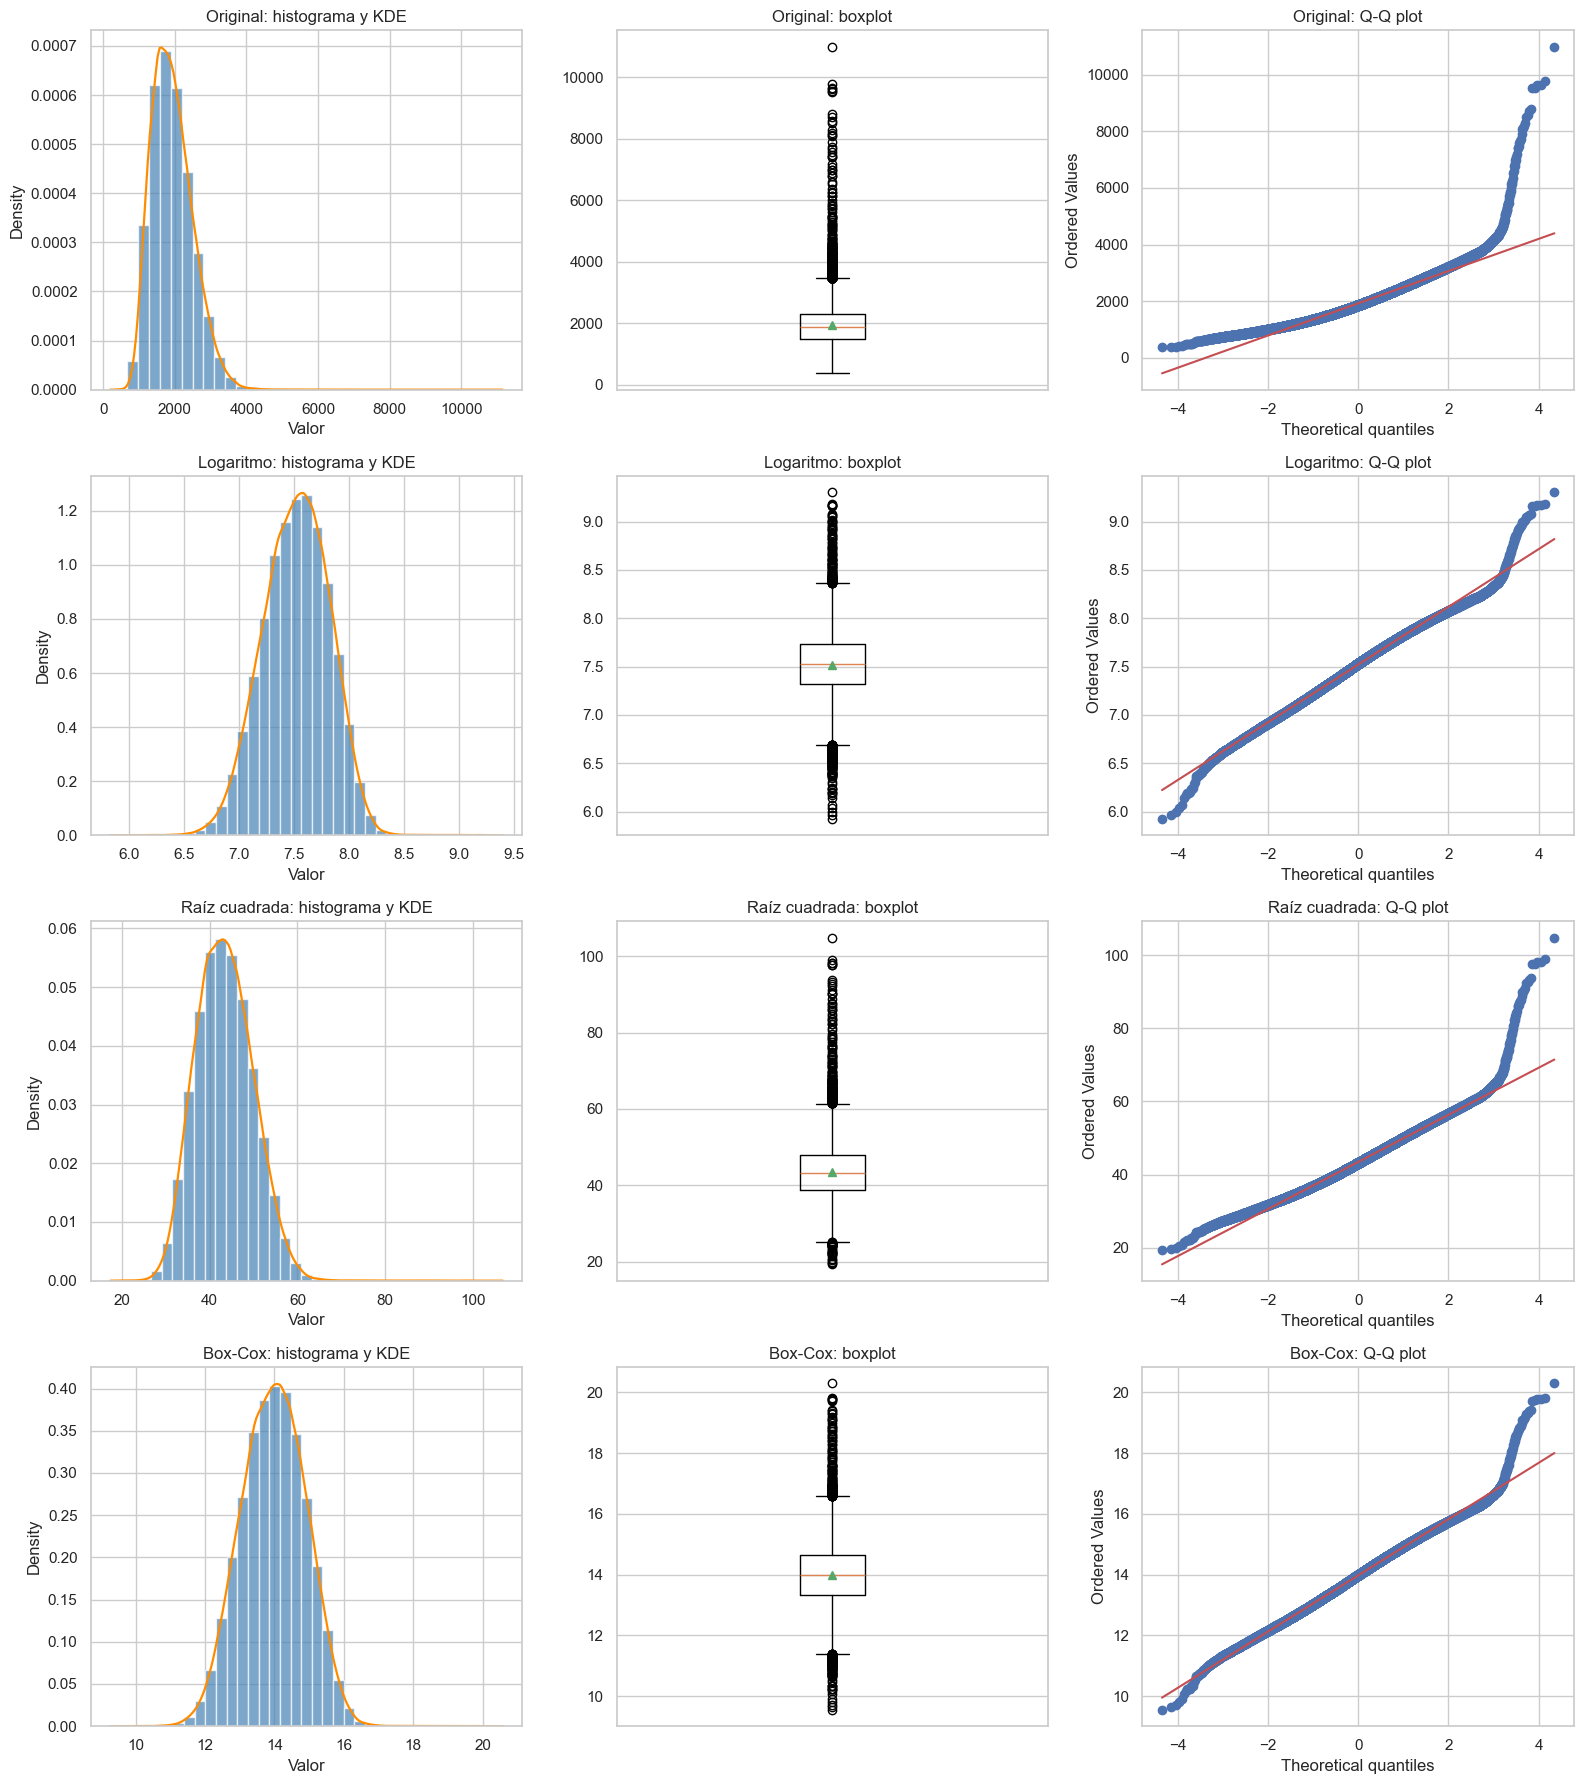

,lambda_boxcox
weight_kg,-0.4804
power_watts,-0.1650
price,0.1504


In [8]:
log_transformer = FunctionTransformer(np.log1p, validate=True)
sqrt_transformer = FunctionTransformer(np.sqrt, validate=True)
boxcox_transformer = PowerTransformer(method='box-cox', standardize=False)

price_original = compu_transf[['price']]
transformaciones_price = {
    'Original': price_original.to_numpy().ravel(),
    'Logaritmo': log_transformer.fit_transform(price_original).ravel(),
    'Raíz cuadrada': sqrt_transformer.fit_transform(price_original).ravel(),
    'Box-Cox': boxcox_transformer.fit_transform(price_original).ravel()
}

def cantidad_outliers(valores):
    serie = pd.Series(valores)
    q1 = serie.quantile(0.25)
    q3 = serie.quantile(0.75)
    iqr = q3 - q1
    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr
    return int(((serie < limite_inferior) | (serie > limite_superior)).sum())

resumen_transformaciones = pd.DataFrame({
    nombre: {
        'skew': pd.Series(valores).skew(),
        'outliers': cantidad_outliers(valores)
    }
    for nombre, valores in transformaciones_price.items()
}).T

display(resumen_transformaciones)

fig, axes = plt.subplots(4, 3, figsize=(16, 18))
for fila, (nombre, valores) in enumerate(transformaciones_price.items()):
    axes[fila, 0].hist(valores, bins=35, density=True, alpha=0.7, color='steelblue', edgecolor='white')
    sns.kdeplot(x=valores, ax=axes[fila, 0], color='darkorange', linewidth=1.6)
    axes[fila, 0].set_title(f'{nombre}: histograma y KDE')
    axes[fila, 0].set_xlabel('Valor')

    axes[fila, 1].boxplot(valores, vert=True, showmeans=True)
    axes[fila, 1].set_title(f'{nombre}: boxplot')
    axes[fila, 1].set_xticks([])

    probplot(valores, dist='norm', plot=axes[fila, 2])
    axes[fila, 2].set_title(f'{nombre}: Q-Q plot')

plt.tight_layout()
plt.show()

columnas_boxcox = ['weight_kg', 'power_watts', 'price']
transformadores_boxcox = {}
lambdas_boxcox = {}

for columna in columnas_boxcox:
    transformador = PowerTransformer(method='box-cox', standardize=False)
    compu_transf[columna] = transformador.fit_transform(
        compu_transf[[columna]]
    ).ravel()
    transformadores_boxcox[columna] = transformador
    lambdas_boxcox[columna] = transformador.lambdas_[0]

display(pd.Series(lambdas_boxcox, name='lambda_boxcox').to_frame())

**Conclusión.** Box-Cox produce el mejor resultado para `price`: reduce el sesgo de aproximadamente 0.987 a un valor prácticamente nulo y disminuye los valores atípicos por IQR de 976 a 317. La transformación logarítmica también corrige el sesgo, pero lo desplaza ligeramente hacia valores negativos; la raíz cuadrada conserva mayor asimetría. Por consistencia se aplica Box-Cox a `weight_kg`, `power_watts` y `price`, todas estrictamente positivas.

7. Para que todas las variables numéricas estén en la misma escala, aplica `MinMaxScaler` de sklearn a todas las columnas numéricas del dataframe, reemplazando las columnas originales.

In [9]:
columnas_numericas = compu_transf.select_dtypes(include=np.number).columns.tolist()
escalador_numerico = MinMaxScaler()
compu_transf[columnas_numericas] = escalador_numerico.fit_transform(
    compu_transf[columnas_numericas]
)

verificacion_escala = pd.DataFrame({
    'minimo': compu_transf[columnas_numericas].min(),
    'maximo': compu_transf[columnas_numericas].max()
})
display(verificacion_escala)

,minimo,maximo
cpu_tier,0.0000,1.0000
cpu_threads,0.0000,1.0000
gpu_tier,0.0000,1.0000
vram_gb,0.0000,1.0000
storage_gb,0.0000,1.0000
storage_drive_count,0.0000,1.0000
bluetooth,0.0000,1.0000
weight_kg,0.0000,1.0000
warranty_months,0.0000,1.0000
price,0.0000,1.0000


**Análisis.** Todas las variables numéricas, incluidas las transformadas y el bin ordinal de VRAM, quedan en el intervalo [0, 1]. El escalamiento evita que las magnitudes originales dominen algoritmos sensibles a distancia o gradiente y conserva el orden relativo de los valores.

8. Aunque `wifi` es una variable categórica, sus categorías tienen un orden natural (Wi-Fi 5 < Wi-Fi 6 < Wi-Fi 6E < Wi-Fi 7). Codifícala usando `OrdinalEncoder`.
* Luego, escala la variable codificada entre 0 y 1 con `MinMaxScaler`, para que quede en la misma escala que las variables numéricas del dataframe.

Nota: Ambos cambios deben efectuarse sobre la columna original, de manera que quede una única columna `wifi` con toda la información transformada.

In [10]:
orden_wifi = [['Wi-Fi 5', 'Wi-Fi 6', 'Wi-Fi 6E', 'Wi-Fi 7']]
encoder_wifi = OrdinalEncoder(categories=orden_wifi)
compu_transf['wifi'] = encoder_wifi.fit_transform(compu_transf[['wifi']]).ravel()

escalador_wifi = MinMaxScaler()
compu_transf[['wifi']] = escalador_wifi.fit_transform(compu_transf[['wifi']])

mapeo_wifi = pd.DataFrame({
    'categoria': orden_wifi[0],
    'valor_escalado': [0, 1/3, 2/3, 1]
})
display(mapeo_wifi)
display(compu_transf[['wifi']].describe().T)

,categoria,valor_escalado
0,Wi-Fi 5,0.0000
1,Wi-Fi 6,0.3333
2,Wi-Fi 6E,0.6667
3,Wi-Fi 7,1.0000


,count,mean,std,min,25%,50%,75%,max
wifi,"100,000.0000",0.4067,0.2848,0.0000,0.3333,0.3333,0.6667,1.0000


**Análisis.** La codificación respeta el orden técnico Wi-Fi 5 < Wi-Fi 6 < Wi-Fi 6E < Wi-Fi 7. Después del escalamiento, las categorías se representan como 0, 0.333, 0.667 y 1, manteniendo tanto el orden como la compatibilidad con el resto de predictores numéricos.

9. La variable `gpu_model` tiene muchas categorías. Usar *One-Hot Encoding* aumentaría significativamente la dimensionalidad del dataframe. Por ello, utiliza `BinaryEncoder` para codificarla.
* Guarda el resultado en un dataframe llamado `bin_df`. Más adelante, lo combinarás con `compu_transf` para integrar las variables codificadas.

In [11]:
encoder_binario = BinaryEncoder(cols=['gpu_model'], return_df=True)
bin_df = encoder_binario.fit_transform(compu_transf[['gpu_model']])
bin_df.index = compu_transf.index

print(f'Dimensiones de bin_df: {bin_df.shape}')
display(bin_df.head())

Dimensiones de bin_df: (100000, 6)


,gpu_model_0,gpu_model_1,gpu_model_2,gpu_model_3,gpu_model_4,gpu_model_5
0,0,0,0,0,0,1
1,0,0,0,0,1,0
2,0,0,0,0,1,1
3,0,0,0,1,0,0
4,0,0,0,1,0,1


**Análisis.** `gpu_model` contiene 49 categorías. La codificación binaria necesita solamente seis columnas para representarlas, frente a las 49 columnas que produciría una codificación completa. Esto reduce la dimensionalidad sin conservar la etiqueta textual original.

10. Usa `OneHotEncoder` para codificar las variables categóricas restantes. Asegúrate de usar `drop='first'` para evitar la multicolinealidad y guarda el resultado en un dataframe llamado `ohe_df`
* Combina el dataframe `compu_transf` con las variables categóricas que fueron codificadas en `bin_df` y `ohe_df`. No olvides eliminar las variables originales.
* Usa `describe()` sobre el dataframe resultante para corroborar que todas las columnas estén escaladas entre 0 y 1 y que no queden variables categóricas sin codificar.

In [12]:
categoricas_restantes = [
    columna
    for columna in compu_transf.select_dtypes(include=['object', 'category']).columns
    if columna != 'gpu_model'
]

try:
    encoder_ohe = OneHotEncoder(
        drop='first',
        sparse_output=False,
        handle_unknown='ignore',
        dtype=np.float64
    )
except TypeError:
    encoder_ohe = OneHotEncoder(
        drop='first',
        sparse=False,
        handle_unknown='ignore',
        dtype=np.float64
    )

matriz_ohe = encoder_ohe.fit_transform(compu_transf[categoricas_restantes])
ohe_df = pd.DataFrame(
    matriz_ohe,
    columns=encoder_ohe.get_feature_names_out(categoricas_restantes),
    index=compu_transf.index
)

base_numerica = compu_transf.drop(
    columns=categoricas_restantes + ['gpu_model']
)
compu_final = pd.concat([base_numerica, bin_df, ohe_df], axis=1)
compu_final = compu_final.clip(lower=0, upper=1)

print(f'Dimensiones de ohe_df: {ohe_df.shape}')
print(f'Dimensiones del dataframe final: {compu_final.shape}')
print(f'Columnas no numéricas restantes: {compu_final.select_dtypes(exclude=np.number).shape[1]}')
print(f'Todas las columnas están entre 0 y 1: {bool(((compu_final.min() >= 0) & (compu_final.max() <= 1)).all())}')

display(compu_final.head())
display(compu_final.describe().T[['min', 'max', 'mean', 'std']])

Dimensiones de ohe_df: (100000, 35)
Dimensiones del dataframe final: (100000, 54)
Columnas no numéricas restantes: 0
Todas las columnas están entre 0 y 1: True


,cpu_tier,cpu_threads,gpu_tier,vram_gb,storage_gb,storage_drive_count,wifi,bluetooth,weight_kg,warranty_months,price,years_since_release,power_watts,gpu_model_0,gpu_model_1,gpu_model_2,gpu_model_3,gpu_model_4,gpu_model_5,device_type_Laptop,brand_Acer,brand_Apple,brand_Dell,brand_Gigabyte,brand_HP,brand_Lenovo,brand_MSI,brand_Razer,brand_Samsung,os_Linux,os_Windows,os_macOS,form_factor_ATX,form_factor_Full-Tower,form_factor_Gaming,form_factor_Mainstream,form_factor_Micro-ATX,form_factor_Mini-ITX,form_factor_SFF,form_factor_Ultrabook,form_factor_Workstation,cpu_brand_Apple,cpu_brand_Intel,gpu_brand_Apple,gpu_brand_Intel,gpu_brand_NVIDIA,storage_type_Hybrid,storage_type_NVMe,storage_type_SSD,display_type_LED,display_type_Mini-LED,display_type_OLED,display_type_QLED,display_type_VA
0,0.4000,0.3846,0.2000,0.6667,0.2000,0.0000,0.3333,0.8182,0.9330,0.6667,0.3287,0.4286,0.8879,0,0,0,0,0,1,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000
1,0.6000,0.3846,0.6000,1.0000,0.0667,0.0000,0.3333,1.0000,0.4237,0.0000,0.4712,0.4286,0.3572,0,0,0,0,1,0,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000
2,0.2000,0.2308,0.0000,0.3333,0.0667,0.3333,0.3333,0.7273,0.8344,0.3333,0.4152,0.1429,0.9186,0,0,0,0,1,1,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000
3,0.2000,0.1538,0.2000,0.6667,0.0667,0.3333,0.3333,0.9091,0.7955,0.6667,0.3181,0.1429,0.8520,0,0,0,1,0,0,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
4,0.8000,0.5385,0.8000,1.0000,0.0000,0.0000,0.3333,0.9091,0.2804,0.0000,0.5208,0.1429,0.2584,0,0,0,1,0,1,1.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000


,min,max,mean,std
cpu_tier,0.0000,1.0000,0.4307,0.2746
cpu_threads,0.0000,1.0000,0.2956,0.1869
gpu_tier,0.0000,1.0000,0.3983,0.2919
vram_gb,0.0000,1.0000,0.5959,0.3942
storage_gb,0.0000,1.0000,0.1687,0.2016
storage_drive_count,0.0000,1.0000,0.1750,0.2658
wifi,0.0000,1.0000,0.4067,0.2848
bluetooth,0.0000,1.0000,0.8043,0.2236
weight_kg,0.0000,1.0000,0.5170,0.2940
warranty_months,0.0000,1.0000,0.2833,0.2842


**Resultado final.** Las variables categóricas restantes se codifican con One-Hot Encoding y `drop='first'`, lo que evita una columna redundante por variable. El dataframe final contiene únicamente valores numéricos; las variables continuas, ordinales y binarias están dentro del intervalo [0, 1]. La estructura queda lista para utilizarse en modelos predictivos sin categorías de texto pendientes.